# 14. Intermittent demand

Sparse demand series (slow-moving items, spare parts) have many zeros. Continuous-level models go wrong on them in two ways: they forecast zero almost always (and get most of the days without sales right) or they spread out a mean that never happens. Intermittent demand methods separate **when** demand happens from **how much** it is.

| Method | Idea |
|---|---|
| `croston_sba` | smooths sizes and intervals between demands; forecast `(1 − α/2) · z / p` |
| `tsb` | smooths the demand probability every period and the size when there is demand; decays when demand stops |
| `adida` | sums in blocks of `k` periods (`k` = mean interval in the training data), smooths the blocks and divides by `k` |
| `imapa` | mean of ADIDA at levels `1..k` |

They make up the `intermittent` family, outside the default search. This notebook also shows why the metric matters: with many zeros, absolute-error metrics (MASE, MAE) reward forecasting zero; **RMSSE** (scaled squared error) rewards getting the mean level right.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.adapters.intermittent import demand_profile
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def clean(ax, grid_axis="both"):
    """Recessive grid and axes; text in neutral ink."""
    ax.grid(axis=grid_axis, color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Data

Synthetic daily series: there is a sale on ~25% of days, and the size of each sale is 1 + Poisson(3). The profile shows the fraction of zeros, the average demand interval (ADI) and the CV² of the sizes; ADI > 1.32 with CV² < 0.49 is the "intermittent" quadrant of Syntetos-Boylan.

{'zero_share': 0.736, 'adi': 3.697, 'cv2': 0.162}


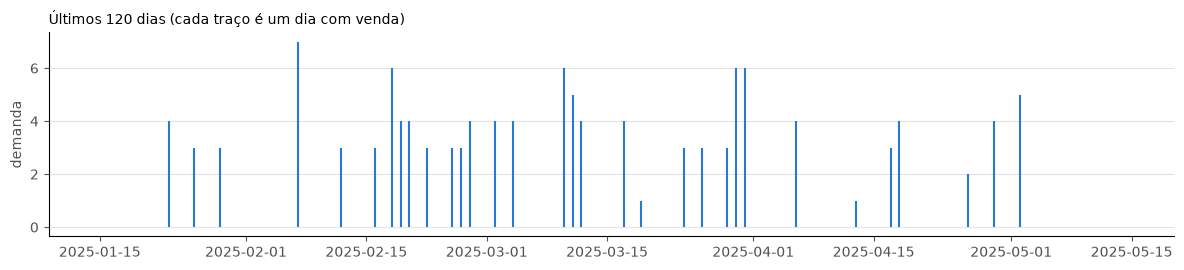

In [2]:
y = get_data("intermittent_daily", n=500)
print({name: round(value, 3) for name, value in demand_profile(y.to_numpy()).items()})
fig, ax = plt.subplots(figsize=(12, 2.8))
recent = y.iloc[-120:]
ax.vlines(recent.index, 0, recent, color="#2a78d6", linewidth=1.5)
ax.set_ylabel("demand", color="#52514e")
ax.set_title("Last 120 days (each mark is a day with a sale)", loc="left", fontsize=10)
clean(ax, grid_axis="y")
fig.tight_layout()

## 2. Each model on the same origins

Mean RMSSE, MASE and MAE on `V_select` (3 origins of 14 days). `naive`, `historic_average` and a 28-day `window_average` are included as references.

In [3]:
exp = AutoHybridExperiment(fh=14, fold=3, session_id=42, metrics=["RMSSE", "MASE", "MAE"]).fit(y)
candidates = {
    "naive": {},
    "historic_average": {},
    "window_average": {"window": 28},
    "croston_sba": {},
    "tsb": {},
    "adida": {},
    "imapa": {},
}
rows = []
for name, params in candidates.items():
    frame = exp.create_model(name, **params).evaluation.to_frame()
    select = frame.loc[frame["layer"] == "select"]
    rows.append({"model": name, **select[["RMSSE", "MASE", "MAE"]].mean().to_dict()})
scores = pd.DataFrame(rows).set_index("model")
scores.round(3).sort_values("RMSSE")

,RMSSE,MASE,MAE
model,,,
historic_average,0.586,0.800,1.450
naive,0.597,0.564,1.024
adida,0.605,0.858,1.555
window_average,0.609,0.874,1.585
croston_sba,0.609,0.855,1.551
imapa,0.615,0.871,1.580
tsb,0.624,0.883,1.601


The order changes with the metric. By MASE, `naive` usually wins: the last value is almost always zero, and forecasting zero gets the days without sales right. By RMSSE, which penalizes deviations from the mean level, `naive` drops. In this series the demand rate is **constant** (an independent draw each day): the training mean (`historic_average`) is the best possible forecast for squared error, and the intermittent methods, which adapt to the recent past, pay for that adaptation with variance.

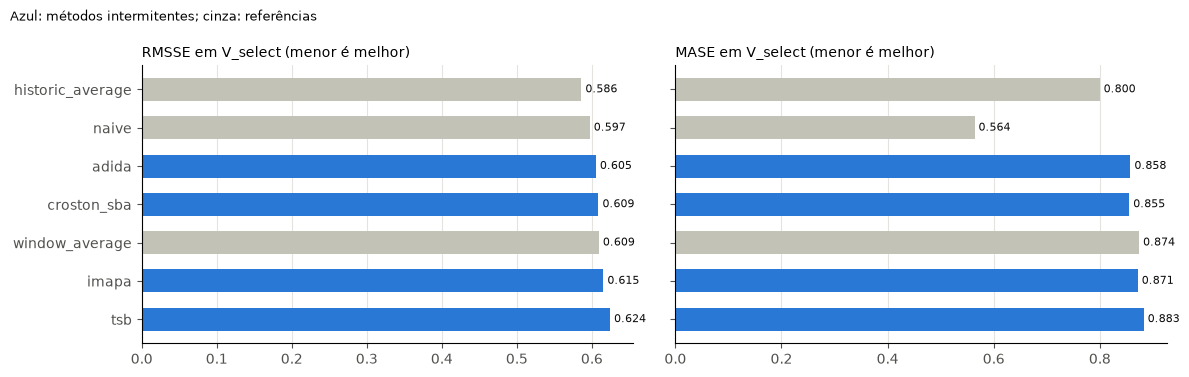

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = scores.sort_values("RMSSE").index[::-1]
intermittent = {"croston_sba", "tsb", "adida", "imapa"}
colors = ["#2a78d6" if name in intermittent else "#c3c2b7" for name in order]
for ax, metric in zip(axes, ["RMSSE", "MASE"], strict=True):
    values = scores.loc[order, metric]
    ax.barh(order, values, color=colors, height=0.6)
    for row, value in enumerate(values):
        ax.text(value, row, f" {value:.3f}", va="center", fontsize=8, color="#0b0b0b")
    ax.set_title(f"{metric} on V_select (lower is better)", loc="left", fontsize=10)
    clean(ax, grid_axis="x")
fig.suptitle("Blue: intermittent methods; grey: references", x=0.01, ha="left", fontsize=9)
fig.tight_layout()

## 3. When the demand rate changes

Intermittent methods exist for demand whose rate changes. Below, three series (seeds 1 to 3) with a sale on 10% of days in the first 380 days and on 40% in the last 120: the validation origins fall after the change. We show all three seeds, not the most favourable one.

In [5]:
def shifted(seed):
    calm = get_data("intermittent_daily", n=380, seed=seed, probability=0.1)
    busy = get_data("intermittent_daily", n=120, seed=seed + 100, probability=0.4)
    index = pd.date_range("2024-01-01", periods=500, freq="D")
    return pd.Series(np.concatenate([calm, busy]), index=index, name="value")


def select_rmsse(experiment, name, params):
    frame = experiment.create_model(name, **params).evaluation.to_frame()
    return frame.loc[frame["layer"] == "select", "RMSSE"].mean()


rows = {}
for seed in (1, 2, 3):
    shift_exp = AutoHybridExperiment(fh=14, fold=3, session_id=42, metrics=["RMSSE"])
    shift_exp.fit(shifted(seed))
    rows[f"seed {seed}"] = {
        name: select_rmsse(shift_exp, name, params) for name, params in candidates.items()
    }
shift = pd.DataFrame(rows)
shift["mean"] = shift.mean(axis=1)
shift.round(3).sort_values("mean")

,seed 1,seed 2,seed 3,mean
croston_sba,1.045,1.238,0.802,1.028
adida,1.034,1.259,0.799,1.031
imapa,1.060,1.230,0.803,1.031
window_average,1.095,1.205,0.803,1.034
tsb,1.134,1.224,0.796,1.051
historic_average,1.064,1.388,0.813,1.088
naive,1.678,1.557,0.931,1.389


## 4. TSB and Croston when demand stops

Croston only updates when there is a sale: if demand vanishes, it keeps the last rate forever. TSB updates the probability every day and decays. Below, both models fitted on the same training data forecast from longer and longer contexts in which the last days are zeros (frozen parameters, no refitting: that is how they work in variant B).

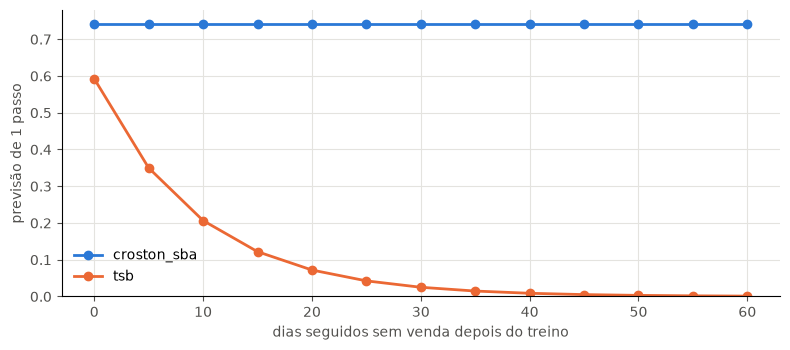

In [6]:
from autohybts.residuals.generation import local_context

train = y.to_numpy()[:400]
models = {name: exp.registry_.make_base(name).fit(train) for name in ["croston_sba", "tsb"]}
quiet = np.concatenate([train, np.zeros(60)])
days = np.arange(0, 61, 5)
fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, model), color in zip(models.items(), ["#2a78d6", "#eb6834"], strict=True):
    path = [model.predict(1, local_context(quiet, 400 + d))[0] for d in days]
    ax.plot(days, path, marker="o", color=color, linewidth=2, label=name)
ax.set_xlabel("consecutive days without a sale after training", color="#52514e")
ax.set_ylabel("1-step forecast", color="#52514e")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
clean(ax)
fig.tight_layout()

## 5. Search and selection with the `intermittent` family

With some intermittent method in `base_models`, the family joins the chain right before the residual hybrids and challenges the champion under the same acceptance rule. The first metric (`RMSSE`) ranks and decides.

In [7]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    budget="small",
    metrics=["RMSSE", "MASE"],
    base_models=["naive", "seasonal_naive", "linear", "croston_sba", "tsb", "adida", "imapa"],
    correctors=["linear"],
    residual_windows=[14],
    alphas=[1.0],
).fit(y)
result = search.compare_models()
print("chain order:", search.policy_.family_order)
print("champion:", result.best.label)
result.decisions[
    [
        "family",
        "champion_before",
        "challenger",
        "accepted",
        "reason_codes",
        "median_gain",
        "win_rate",
    ]
]

chain order: ('statistical', 'linear', 'kernel', 'tree', 'neural', 'intermittent', 'residual', 'decomposition', 'combination', 'dynamic')
champion: tsb


,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate
0,statistical,tsb,naive,False,"(median_gain_below_threshold, win_rate_below_t...",-0.024991,0.333333
1,linear,tsb,linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.013341,0.333333
2,residual,tsb,linear-linear,False,"(median_gain_below_threshold,)",0.048717,0.666667


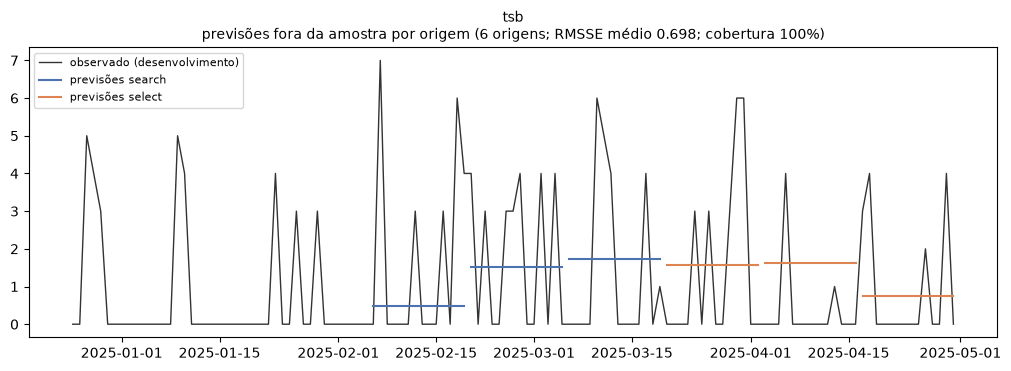

In [8]:
search.plot_model(result.best, "cv_forecasts")

## 6. External evaluation of the champion

A single reading of the sealed test, after freezing the choice.

In [9]:
final = search.finalize_model(result.best)
search.evaluate_external(final).metrics.round(3)

,RMSSE,MASE
model,,
tsb,0.495,0.639


## 7. Reading

In this run (500 days, `fh=14`, 3 origins per layer):

* **The series is intermittent** by the Syntetos-Boylan criterion: 74% zeros, average demand interval of 3.7 days, CV² of the sizes 0.16.
* **The metric decides who wins.** By MASE, `naive` wins (0.56 against 0.80–0.88 for the others) because it forecasts zero on most days. By RMSSE, `naive` drops to second place.
* **With a constant rate, the historical mean is the best control.** `historic_average` had RMSSE 0.586; the intermittent methods ranged from 0.605 (`adida`) to 0.624 (`tsb`). None beat the training mean: with stationary demand, adapting to the recent past only adds variance.
* **With a rate change, they pay off, but not alone.** In the three seeds with the rate going from 10% to 40%, `croston_sba`, `adida` and `imapa` had a mean RMSSE of 1.03, against 1.09 for `historic_average` and 1.39 for `naive`; the 28-day moving average (1.03) tied with them. The gain comes from forgetting the past, which a window average also does.
* **TSB and Croston diverge when demand stops:** after 60 days without a sale, TSB forecasts practically zero and Croston keeps 0.74 per day.
* **In the search**, TSB was the best standalone model of the search and became the initial champion (no other standalone model beat it on `V_select`); a `linear-linear` hybrid won 2 out of 3 units with a median gain of 4.9%, below the 5% minimum, and was rejected: TSB remained champion (RMSSE 0.495 on the sealed test). The series has no structure beyond the mean rate; under the previous rule (gain ≥ 1%) this hybrid would have been accepted, a typical false acceptance with 3 units in `V_select` (notebook 11, ADR-0008).

For sparse demand, always compare with `historic_average` and `window_average`, use RMSSE (or another squared-error metric) for ranking and increase `fold` before trusting an acceptance.